# RNN sentiment analysis with Keras

Same task again (50 labelled sentences, positive vs negative), now using Keras layers and `model.fit`.

| From scratch (NumPy) | Keras |
|---|---|
| Vocabulary and word-to-id mapping | `TextVectorization` |
| Embedding table `E` | `layers.Embedding` |
| tanh RNN cell loop (`W`, `U`, `b`) | `layers.SimpleRNN` |
| Output weights `V`, `c` + sigmoid | `layers.Dense(1, activation="sigmoid")` |
| Loss, backpropagation through time, update | `compile` + `fit` |
| Gradient clipping | `Adam(clipnorm=5.0)` |

Install if needed: `pip install tensorflow matplotlib`

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Dataset (50 sentences)

In [5]:
positive = [
    "i like her attitude", "i love this movie", "i love this song", "i love this book",
    "i like this place", "this movie is great", "this song is great", "this food is delicious",
    "this show is amazing", "this book is amazing", "what a wonderful day", "what a great day",
    "what a wonderful friend", "the service was excellent", "the food was excellent",
    "the show was fantastic", "the movie was fantastic", "i am so happy today",
    "i am very happy with this place", "my friend is awesome", "she is an awesome friend",
    "the day was wonderful", "this food is amazing", "i like her friend", "i love her attitude",
]
negative = [
    "i hate this movie", "i hate this song", "i hate this book", "i hate this place",
    "this movie is terrible", "this song is terrible", "this food is disgusting",
    "this show is boring", "this book is boring", "what a horrible day", "what a terrible day",
    "what a rude friend", "the service was awful", "the food was awful", "the show was bad",
    "the movie was bad", "i am so sad today", "i am very sad with this place",
    "my friend is horrible", "she is a rude friend", "the day was terrible", "this food is awful",
    "i hate her friend", "i hate her attitude", "the day was the worst",
]
texts = positive + negative
labels = np.array([1] * len(positive) + [0] * len(negative), dtype="float32")
print(len(texts), "sentences |", int(labels.sum()), "positive,", int(len(labels) - labels.sum()), "negative")

50 sentences | 25 positive, 25 negative


## 2. Split and vectorize

In [6]:
idx = np.random.permutation(len(texts))
test_idx, train_idx = idx[:10], idx[10:]

train_texts = [texts[i] for i in train_idx]; y_train = labels[train_idx]
test_texts  = [texts[i] for i in test_idx];  y_test  = labels[test_idx]

MAXLEN = max(len(s.split()) for s in train_texts)

# Fit the vocabulary on the training split only. Id 0 is padding, id 1 is [UNK].
vectorizer = layers.TextVectorization(output_mode="int", output_sequence_length=MAXLEN)
vectorizer.adapt(tf.constant(train_texts))

VOCAB = len(vectorizer.get_vocabulary())
X_train = vectorizer(tf.constant(train_texts)).numpy()
X_test  = vectorizer(tf.constant(test_texts)).numpy()
print("vocab size:", VOCAB, "| max length:", MAXLEN, "| train:", len(X_train), "| test:", len(X_test))
print("example:", train_texts[0], "->", X_train[0])

vocab size: 48 | max length: 7 | train: 40 | test: 10
example: what a wonderful friend -> [ 9  8 17  7  0  0  0]


## 3. The model

`Embedding(mask_zero=True)` tells the RNN to skip the padding, so `SimpleRNN` returns the hidden state after the last real word:
$h_t = \tanh(W e_t + U h_{t-1} + b)$, followed by a sigmoid output layer.

In [7]:
model = keras.Sequential([
    keras.Input(shape=(MAXLEN,)),
    layers.Embedding(VOCAB, 16, mask_zero=True),
    layers.SimpleRNN(24, activation="tanh"),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01, clipnorm=5.0),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 7, 16)          │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 24)             │           984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            25 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,777 (6.94 KB)

 Trainable params: 1,777 (6.94 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Training

In [8]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=60,
    batch_size=8,
    verbose=0,
)

h = history.history
for e in [0, 9, 19, 29, 39, 49, 59]:
    print(f"epoch {e + 1:3d} | train loss {h['loss'][e]:.3f} acc {h['accuracy'][e]:.2f}"
          f" | test loss {h['val_loss'][e]:.3f} acc {h['val_accuracy'][e]:.2f}")

epoch   1 | train loss 0.694 acc 0.50 | test loss 0.761 acc 0.30
epoch  10 | train loss 0.002 acc 1.00 | test loss 3.893 acc 0.30
epoch  20 | train loss 0.000 acc 1.00 | test loss 4.041 acc 0.30
epoch  30 | train loss 0.000 acc 1.00 | test loss 4.088 acc 0.30
epoch  40 | train loss 0.000 acc 1.00 | test loss 4.118 acc 0.30
epoch  50 | train loss 0.000 acc 1.00 | test loss 4.138 acc 0.30
epoch  60 | train loss 0.000 acc 1.00 | test loss 4.154 acc 0.30


## 5. Learning curves

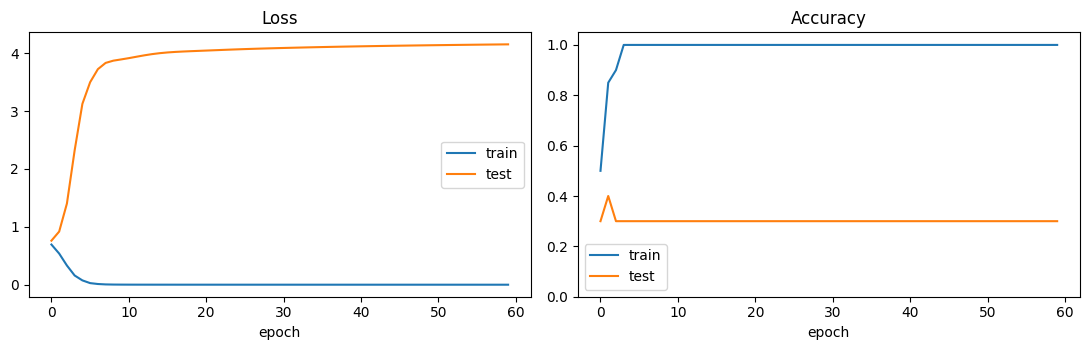

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="test")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="test")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].set_ylim(0, 1.05); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Test set predictions

In [10]:
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"test loss {loss:.3f} | test accuracy {acc:.2f}\n")

probs = model.predict(X_test, verbose=0).ravel()
for s, p, y in zip(test_texts, probs, y_test):
    print(f"{'OK ' if int(p > 0.5) == int(y) else 'BAD'} | p(positive)={p:.2f} | true={int(y)} | {s}")

test loss 4.154 | test accuracy 0.30

BAD | p(positive)=0.06 | true=1 | the service was excellent
BAD | p(positive)=1.00 | true=0 | the show was bad
BAD | p(positive)=0.96 | true=0 | this song is terrible
BAD | p(positive)=0.98 | true=0 | the day was terrible
BAD | p(positive)=0.00 | true=1 | i am so happy today
OK  | p(positive)=0.00 | true=0 | i hate her attitude
OK  | p(positive)=0.00 | true=0 | i hate this song
OK  | p(positive)=0.00 | true=0 | i hate this movie
BAD | p(positive)=1.00 | true=0 | this show is boring
BAD | p(positive)=0.00 | true=1 | my friend is awesome


## 7. Try your own sentence

Words that were not in the training split become `[UNK]` and carry no sentiment, so use words from the dataset for best results.

In [11]:
def predict(sentence):
    ids = vectorizer(tf.constant([sentence])).numpy()
    p = float(model.predict(ids, verbose=0)[0, 0])
    return ("positive" if p > 0.5 else "negative"), p

for s in ["i like her attitude", "this movie is terrible", "what a wonderful friend", "this food is awful"]:
    label, p = predict(s)
    print(f"{s!r:35} -> {label} ({p:.2f})")

'i like her attitude'               -> positive (1.00)
'this movie is terrible'            -> negative (0.00)
'what a wonderful friend'           -> positive (1.00)
'this food is awful'                -> negative (0.00)


## Notes

- The dataset is tiny, so test accuracy on 10 sentences is noisy and changes with the seed.
- Change `layers.SimpleRNN(24)` to `layers.LSTM(24)` or `layers.GRU(24)` to handle longer sentences better. Wrapping it as `layers.Bidirectional(layers.LSTM(24))` reads the sentence in both directions.
- To ship the model, put `vectorizer` as the first layer so it accepts raw strings.